# Análisis teórico e intervalos de confianza

Este cuaderno complementa los tres Tiers sin entrenar agentes. Los tres cuadernos
de trabajo se conservan. Ejecuta las celdas en orden con el kernel del proyecto.
El análisis de dos páginas está también en [PDF](output/pdf/analisis_teorico.pdf).
Las bandas históricas de desviación estándar eran válidas según la guía; aquí
se añaden IC del 95% y se explican sus supuestos.

In [1]:
from pathlib import Path
import sys
from IPython.display import display, Markdown, Image
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / 'report/analisis_teorico.md').exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
def texto(path):
    display(Markdown((ROOT / path).read_text(encoding='utf-8')))
def imagen(path):
    display(Image(filename=str(ROOT / path)))
print('Solo lectura de informes y figuras; sin entrenamiento.')

Solo lectura de informes y figuras; sin entrenamiento.


In [2]:
texto('report/analisis_teorico.md')

# Análisis teórico: pertinencia y límites de Q-learning y DQN

Componente obligatorio sin implementación. Se consideran las configuraciones por defecto de Gymnasium 1.4.0: BipedalWalker-v3 y MuJoCo v5. Las dimensiones se contrastaron con la documentación oficial y los archivos de la versión instalada; no se entrenaron estos entornos. Los tamaños de tablas y rejillas siguientes son cálculos propios, no resultados experimentales.

## 1. El algoritmo debe corresponder al espacio de acciones

Q-learning tabular guarda un valor por cada par estado-acción. DQN aproxima esos valores mediante una red, pero su versión estándar entrega un valor por acción discreta y calcula un máximo sobre todas ellas. En CartPole hay dos acciones: la tabla con resolución 2/2/6/6 contiene 144 estados y 288 valores Q. En LunarLander discreto hay ocho componentes observados y cuatro acciones: DQN puede compartir información entre observaciones próximas sin enumerarlas. Dos componentes de LunarLander son indicadores de contacto, por lo que describir las ocho observaciones como ocho variables estrictamente continuas sería impreciso.

En locomoción, las acciones son vectores continuos: especifican simultáneamente controles de varias articulaciones. No hay una lista finita que el DQN estándar pueda enumerar directamente. Si se asignan k niveles a cada una de d componentes, aparecen k^d acciones conjuntas, no k·d. [G1–G4]

| Entorno | Dimensión de observación | Controles d | k=3: acciones | k=5: acciones | k=11: acciones |
|---|---:|---:|---:|---:|---:|
| BipedalWalker-v3 | 24 | 4 | 81 | 625 | 14641 |
| Hopper-v5 | 11 | 3 | 27 | 125 | 1331 |
| HalfCheetah-v5 | 17 | 6 | 729 | 15625 | 1771561 |
| Ant-v5 | 105 | 8 | 6561 | 390625 | 214358881 |

Ant-v5 incluye por defecto 78 componentes de fuerzas de contacto, además de 27 posiciones y velocidades; otros argumentos o versiones cambian esa dimensión. BipedalWalker mezcla magnitudes físicas, contactos y lidar. No todas las observaciones son variables continuas independientes. [G1,G4]

La rejilla de acciones es posible en principio, especialmente para Hopper, pero restringe el control y encarece la búsqueda y la capa de salida de DQN. En Ant, once niveles exigirían más de 214 millones de valores de salida por observación. Una rejilla más gruesa abarata el cálculo a costa de perder precisión; aumentar la resolución produce crecimiento exponencial. No se afirma que discretizar sea matemáticamente imposible, sino poco adecuado para el presupuesto de este proyecto.

## 2. Por qué tampoco escala una tabla de estados

Discretizar m observaciones en b intervalos produce, en una rejilla completa, b^m estados y b^m·k^d valores Q. Para Hopper, diez intervalos por observación y cinco niveles por control dan 10^11·125 entradas: con float32 ocupan 5·10^13 bytes, aproximadamente 50 TB decimales, sin contar estructuras auxiliares. Visitar suficientemente esos pares es aún más costoso. Las correlaciones físicas hacen que parte de la rejilla sea inalcanzable; no eliminan el problema de una tabla densa.

Agrupar estados reduce memoria, pero puede unir situaciones que necesitan acciones distintas: dos velocidades dentro del mismo intervalo pueden requerir correcciones diferentes. Es el compromiso entre resolución y cobertura. Nuestros resultados de CartPole son compatibles con este mecanismo: aumentar intervalos no mejoró automáticamente el retorno bajo 200000 pasos. La observación experimental no identifica una causa única ni demuestra que una granularidad sea universalmente óptima.

## 3. Familias apropiadas para control continuo

- **PPO:** aprende una política parametrizada que puede generar vectores de acciones continuas. Su objetivo recortado limita el incentivo a cambios excesivos de política en los datos usados; no garantiza por sí solo estabilidad. Es una alternativa sencilla de actor-crítico, aunque requiere recoger nuevos datos en sus rondas de optimización. [P1]
- **SAC:** actor-crítico fuera de política, reutiliza experiencia y combina recompensa con entropía. Una política estocástica continua evita enumerar una rejilla y favorece exploración. Es una opción pertinente cuando importa aprovechar interacciones costosas, sin garantizar que siempre supere a PPO. [P2]
- **TD3:** actor continuo determinista y dos críticos; utiliza el menor valor objetivo, actualizaciones retrasadas de la política y suavizado de acciones objetivo para controlar errores de aproximación. También reutiliza experiencia. Comparte la motivación de limitar sobreestimación con Double DQN, pero no es el mismo algoritmo ni convierte Double DQN en un controlador continuo. [P3]

Estas familias resuelven la representación de acciones continuas mediante un actor, no mediante una salida por cada combinación de controles. La elección práctica dependería de coste de interacción, exploración y ajuste; aquí se justifica su pertinencia, sin afirmar rendimientos medidos en nuestros equipos.

## 4. Por qué una tabla tampoco sirve para píxeles de Atari

Considérese una entrada habitual preprocesada de cuatro imágenes de 84×84 en escala de grises: son 28224 componentes con 256 intensidades posibles. El conjunto de todas las combinaciones tiene 256^28224, aproximadamente 10^67970 entradas visuales posibles, antes de multiplicar por acciones. Es una cota combinatoria, no el número de imágenes físicamente alcanzables en un juego. Incluso a un bit por píxel quedarían 2^28224 combinaciones. Reducir colores no vuelve viable una tabla exhaustiva. [G5,G6]

Una tabla tampoco comparte automáticamente lo aprendido entre imágenes parecidas. DQN con una red convolucional comparte rasgos espaciales y aproxima Q sin almacenar un valor distinto para cada imagen. Apilar imágenes aporta información sobre movimiento, aunque no garantiza observabilidad completa. Atari conserva acciones discretas: por eso DQN es pertinente con píxeles, mientras que su dificultad en locomoción incluye además el espacio continuo de acciones. Nuestro MLP de CartPole/LunarLander no constituye por sí solo una implementación DQN para Atari. [P4]

## Referencias verificadas

- [G1] [Gymnasium: BipedalWalker](https://gymnasium.farama.org/environments/box2d/bipedal_walker/).
- [G2] [Gymnasium: Hopper](https://gymnasium.farama.org/environments/mujoco/hopper/).
- [G3] [Gymnasium: HalfCheetah](https://gymnasium.farama.org/environments/mujoco/half_cheetah/).
- [G4] [Gymnasium: Ant](https://gymnasium.farama.org/environments/mujoco/ant/).
- [G5] [Gymnasium: AtariPreprocessing](https://gymnasium.farama.org/api/wrappers/misc_wrappers/).
- [G6] [Gymnasium: FrameStackObservation](https://gymnasium.farama.org/api/wrappers/observation_wrappers/).
- [P1] Schulman et al. (2017). [Proximal Policy Optimization Algorithms](https://arxiv.org/abs/1707.06347).
- [P2] Haarnoja et al. (2018). [Soft Actor-Critic](https://arxiv.org/abs/1801.01290).
- [P3] Fujimoto et al. (2018). [Addressing Function Approximation Error in Actor-Critic Methods](https://arxiv.org/abs/1802.09477).
- [P4] Mnih et al. (2013). [Playing Atari with Deep Reinforcement Learning](https://arxiv.org/abs/1312.5602).

Esta sección satisface el análisis sin implementación; se integrará después en el artículo final de 6–8 páginas. La discusión experimental y los intervalos se presentan por separado para no confundir cálculos de escalabilidad con mediciones de agentes entrenados.


## Cómo leer la incertidumbre

In [3]:
texto('report/intervalos_confianza.md')

# Cómo se calcularon e interpretan los intervalos

## Qué exige la guía

El apartado 6.2 permite **media con desviación estándar o IC del 95%**. Por tanto, las figuras previas con DE ya cumplían ese requisito. Se añaden IC a petición del equipo; esta actualización no requiere entrenar ni generar nuevos episodios. Los pesos, tablas, semillas y retornos originales se conservan.

## Unidad experimental y fórmula

En cada paso de evaluación se calcula primero el retorno medio de los diez episodios de **cada modelo entrenado**. Después se usan las tres medias correspondientes a las semillas 42, 43 y 44. Para entrenamiento, cada réplica aporta su media de episodios completos terminados dentro del bloque de pasos; un episodio cortado por presupuesto no se incluye. En las tablas finales, cada réplica aporta su media de 100 episodios, con igual peso entre semillas.

Con n=3, media m y desviación estándar **muestral** s (ddof=1), se calcula:

**IC 95% = m ± 4.302652729696142 × s / √3.**

El factor corresponde a t de Student con dos grados de libertad, no al factor normal 1.96. Implementación compartida en `experiments/intervalos.py`. Si falta una de las tres réplicas en un punto, no se presenta un IC de tres semillas para ese punto.

Los 300 episodios de tres agentes **no equivalen a 300 entrenamientos independientes**. Tratar todos los episodios como réplicas independientes subestimaría la incertidumbre entre entrenamientos. Las dos muestras nuevas de LunarLander se presentan por separado; no producen seis semillas de entrenamiento.

## Alcance y limitaciones

- Son IC **puntuales** de la media: cada paso se considera por separado. No significan una cobertura conjunta del 95% para toda la curva; los controles sucesivos están correlacionados.
- La interpretación t supone medias por semilla independientes y aproximadamente normales. Con solo tres semillas no se puede comprobar bien esa forma de distribución. Son intervalos orientativos, no una garantía robusta de cobertura en RL.
- Son condicionales al entorno y configuración evaluados. No incorporan toda la incertidumbre de la búsqueda de parámetros ni eliminan el posible optimismo del desarrollo. En LunarLander la selección del checkpoint precedió a ambas muestras nuevas, pero estas evalúan los mismos tres modelos, no nuevas réplicas de entrenamiento.
- **DE e IC son distintos.** Las tablas que dicen “media ± DE” conservan la DE descriptiva previa (ddof=0). Las bandas nuevas se etiquetan explícitamente “IC 95%”. No se reinterpretan cifras históricas de DE como IC.
- No se recortan los extremos para que parezcan más precisos. Un IC simétrico de CartPole puede superar su máximo de 500; ese extremo es una limitación del modelo estadístico, no un retorno observado posible. Cerca del techo y con n=3 conviene priorizar también los valores individuales.
- Que los tres modelos superen el umbral es un hecho descriptivo verificable; no garantiza el éxito de cualquier entrenamiento futuro. Que dos IC se solapen tampoco es por sí solo una prueba de igualdad de algoritmos.

## Comparación emparejada de Tier 3

Para cada semilla se resta DQN a Double DQN en la misma muestra de evaluación. Se calcula el mismo IC t sobre esas **tres diferencias**, manteniendo el emparejamiento. La comparación es exploratoria tras el desarrollo. En la muestra de confirmación el intervalo de la diferencia incluye cero: el resultado no sustenta una afirmación de superioridad general de Double DQN.

## Archivos y reproducción sin entrenamiento

Las figuras de comparación vigentes de CartPole, los cuatro estudios iniciales de LunarLander y las dos curvas de la mejora usan ahora IC. Las barras individuales por semilla se conservan como observaciones, sin confundirlas con una media entre semillas. La figura adicional `results/analisis_intervalos/resultados_ic95.png` muestra IC de las medias finales; las cifras exactas y diferencias emparejadas están en su `summary.json` y `report.md`.

Los comandos completos están en el bloque “Análisis teórico e intervalos” del README. `curves.csv` de Tier 1 y los archivos `*_intervals.csv` de LunarLander guardan los extremos de cada punto. Los tres cuadernos de trabajo del usuario se conservan; `Analisis_Teorico_e_Intervalos.ipynb` reúne el texto y las figuras nuevas sin ejecutar entrenamiento.

## Referencia estadística

[NIST/SEMATECH, Confidence Limits for the Mean](https://www.itl.nist.gov/div898/handbook/eda/section3/eda352.htm): fórmula t y significado frecuentista de cobertura. La fórmula procede de esta referencia; su uso condicionado a tres semillas, la unidad experimental y las limitaciones anteriores son decisiones metodológicas explícitas de este proyecto.


## Cálculo visible: tres semillas, no 300 entrenamientos

In [4]:
import inspect, json
from IPython.display import Code
from experiments.intervalos import mean_ci95
display(Code(inspect.getsource(mean_ci95), language='python'))
datos = json.loads((ROOT / 'results/analisis_intervalos/summary.json').read_text(encoding='utf-8'))
ejemplo = next(r for r in datos['rows'] if r['tier'] == 2 and r['sample'] == 'test')
print('DQN LunarLander, medias individuales:', ejemplo['values'])
media, inferior, superior = mean_ci95(ejemplo['values'])
print(f'Media: {media:.2f}; IC 95% orientativo: [{inferior:.2f}, {superior:.2f}]')

def mean_ci95(values, axis=0):
    """Media y extremos sin recorte. Un punto incompleto queda sin estimación."""
    values = np.asarray(values, dtype=float)
    if values.shape[axis] != 3:
        raise ValueError('Este protocolo requiere exactamente tres semillas independientes.')
    complete = np.isfinite(values).all(axis=axis)
    mean = np.mean(values, axis=axis)
    half = T_975_DF2 * np.std(values, axis=axis, ddof=1) / np.sqrt(3)
    return tuple(np.where(complete, v, np.nan) for v in (mean, mean-half, mean+half))

DQN LunarLander, medias individuales: [272.70260009424294, 277.60800925824617, 267.2472869685826]
Media: 272.52; IC 95% orientativo: [259.64, 285.39]


# Intervalos calculados desde resultados guardados

| Tier | Método | Muestra | Media | IC 95% |
|---|---|---|---:|---:|
| 1 | Q-learning (2/2/6/6 intervalos) | final | 495.73 | [477.36, 514.10] |
| 1 | Q-learning (2/2/10/10 intervalos) | final | 163.84 | [32.43, 295.25] |
| 1 | Q-learning (2/2/20/20 intervalos) | final | 170.21 | [94.55, 245.88] |
| 1 | DQN ajustado | final | 498.60 | [492.56, 504.63] |
| 2 | DQN LunarLander | test | 272.52 | [259.64, 285.39] |
| 2 | DQN LunarLander | confirmation | 273.69 | [261.28, 286.10] |
| 3 | Double DQN LunarLander | test | 277.37 | [263.11, 291.63] |
| 3 | Double DQN LunarLander | confirmation | 278.07 | [269.06, 287.08] |

## Diferencias emparejadas: Double menos DQN

Cada diferencia usa la misma semilla y muestra de evaluación. No se combinan las dos muestras.

| Muestra | Diferencia media | IC 95% |
|---|---:|---:|
| test_mean | +4.85 | [2.14, 7.56] |
| confirmation_mean | +4.38 | [-6.51, 15.27] |

Con tres semillas estos IC dependen fuertemente del supuesto de normalidad. La comparación es exploratoria y posterior al desarrollo; no constituye una prueba confirmatoria universal.
En la confirmación el IC de la diferencia incluye cero. Los seis modelos superan individualmente 200 en ambas muestras; ese hecho descriptivo no depende de que el IC entre algoritmos excluya cero.
Método y límites: report/intervalos_confianza.md. No se ejecutó ningún entrenamiento para producir estas figuras.


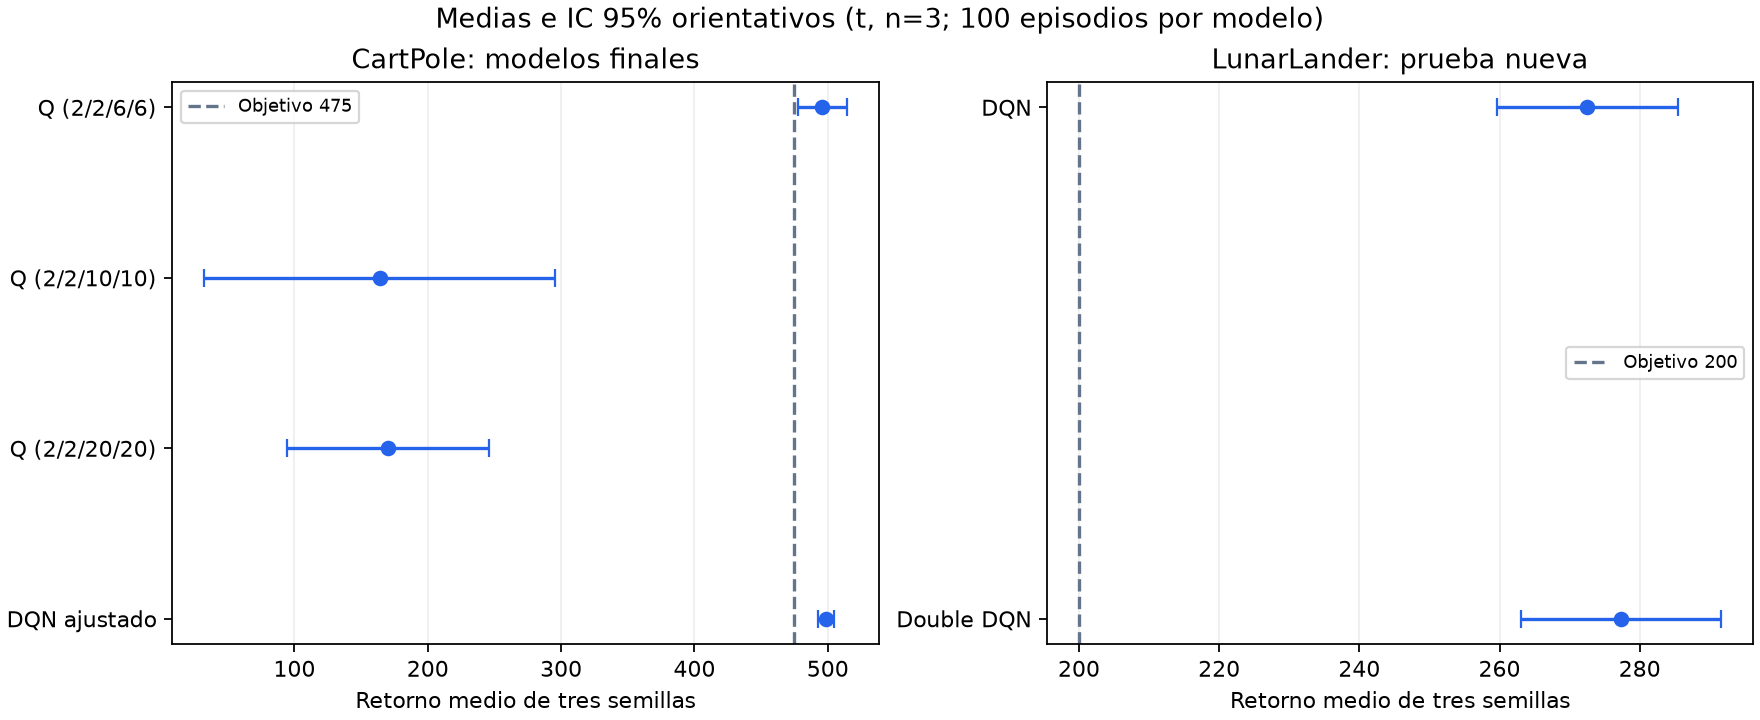

In [5]:
texto('results/analisis_intervalos/report.md')
imagen('results/analisis_intervalos/resultados_ic95.png')

## Tier 1: mismo presupuesto, tres granularidades y DQN

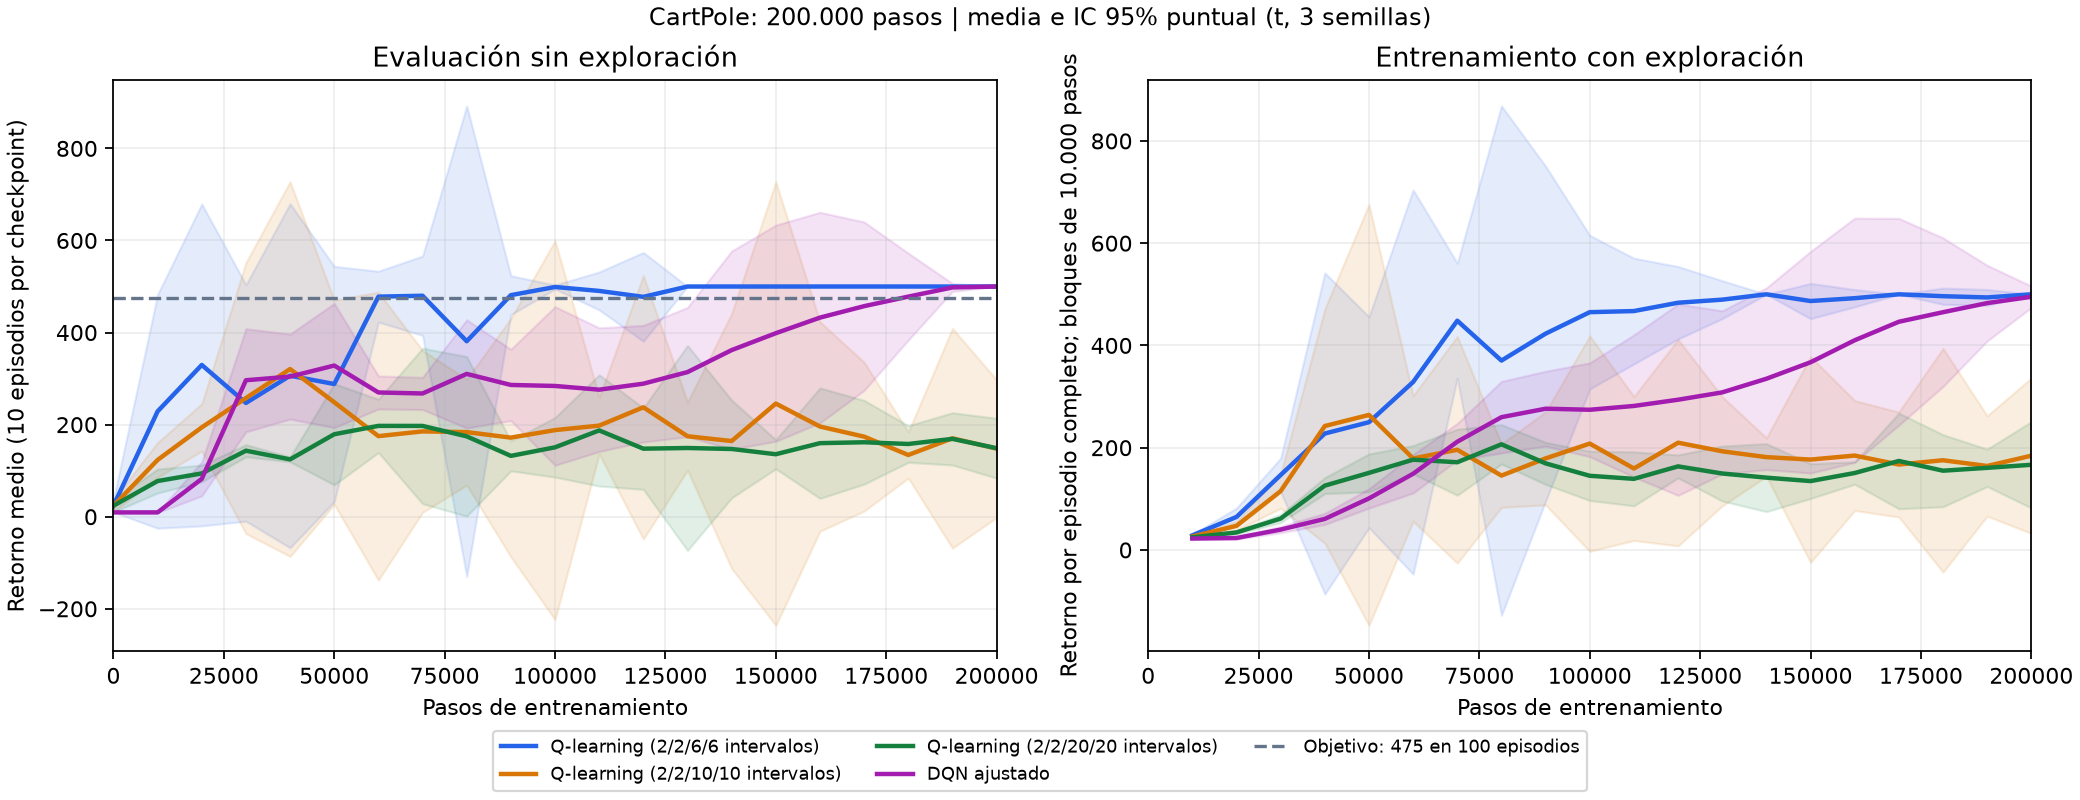

In [6]:
imagen('results/parte_18_qlearning/comparacion/tier1_comparacion.png')

## Estudios iniciales: hiperparámetros y ablación de Tier 2; comparación de Tier 3

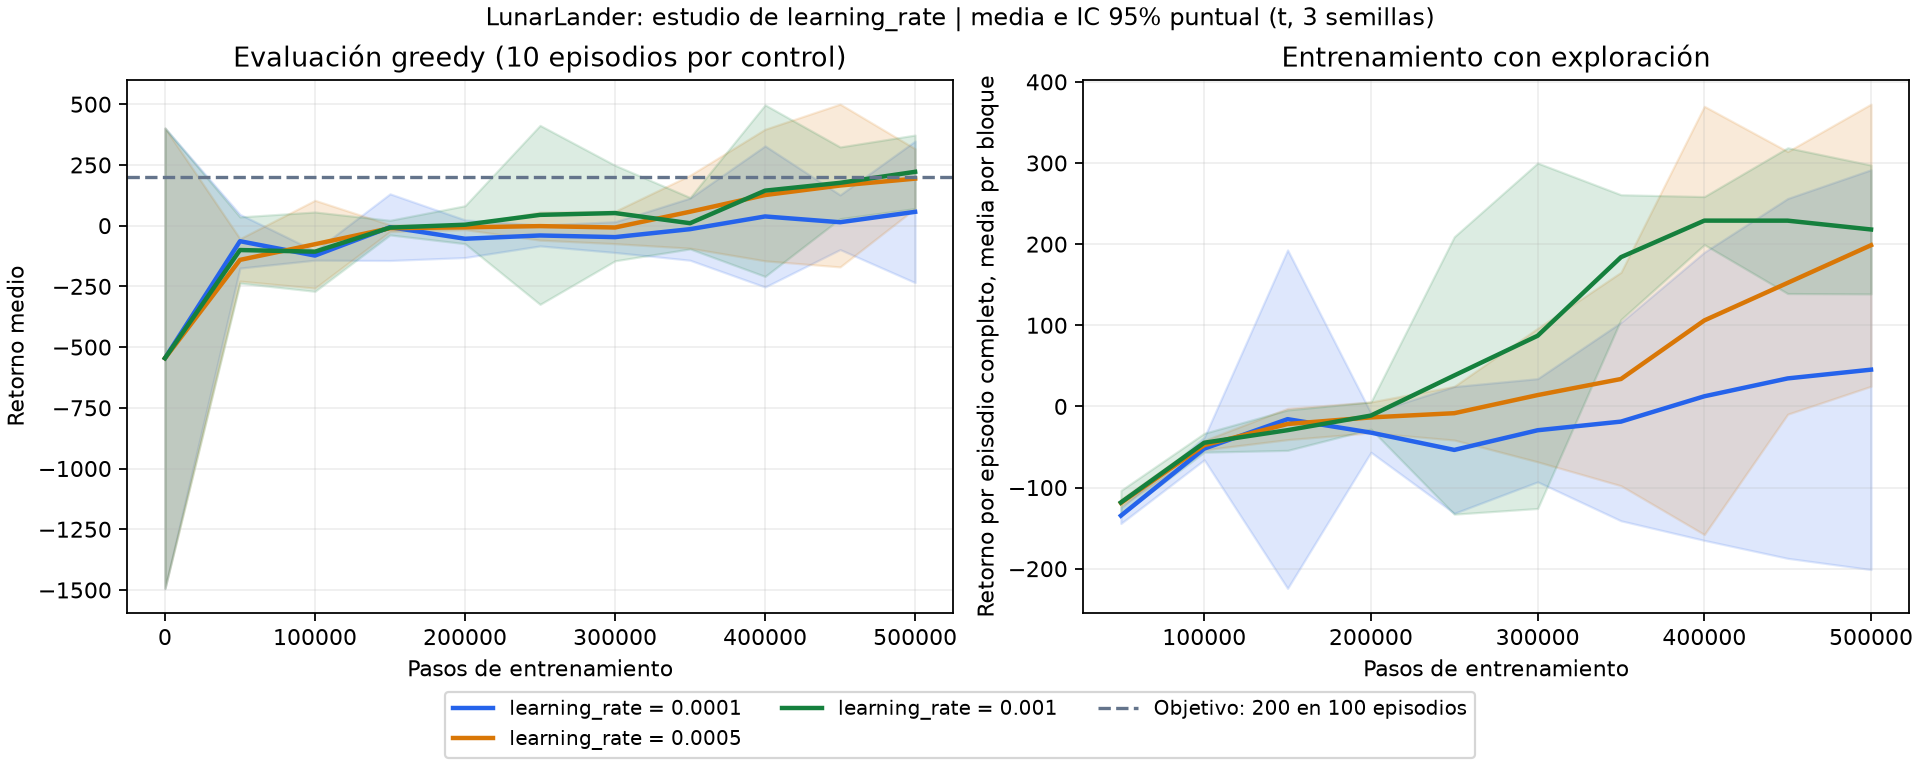

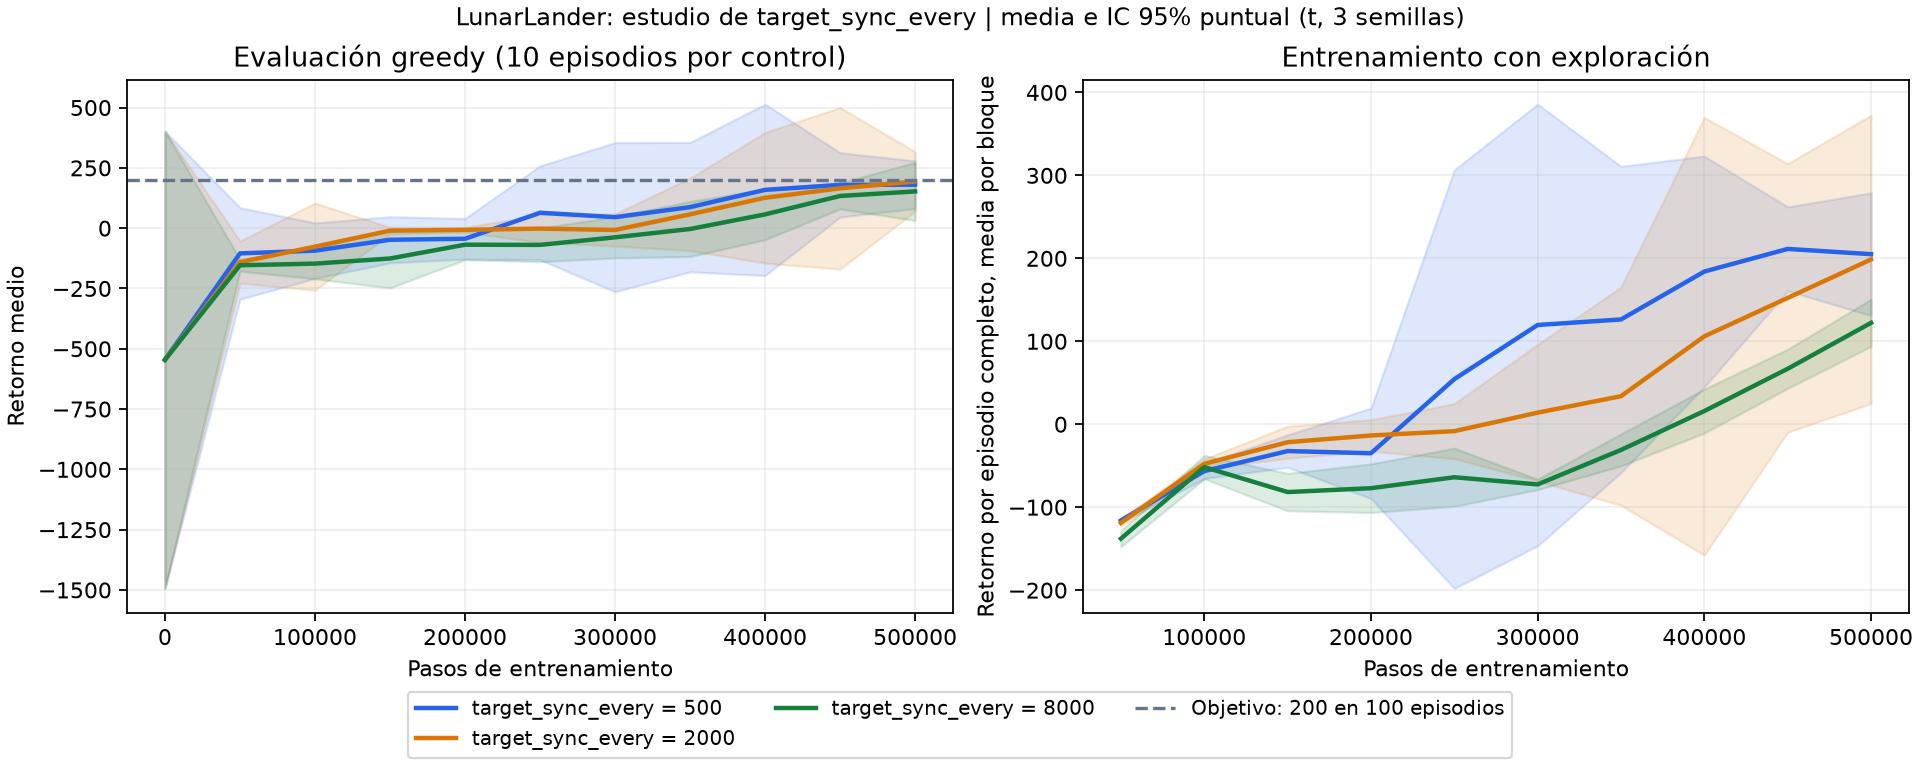

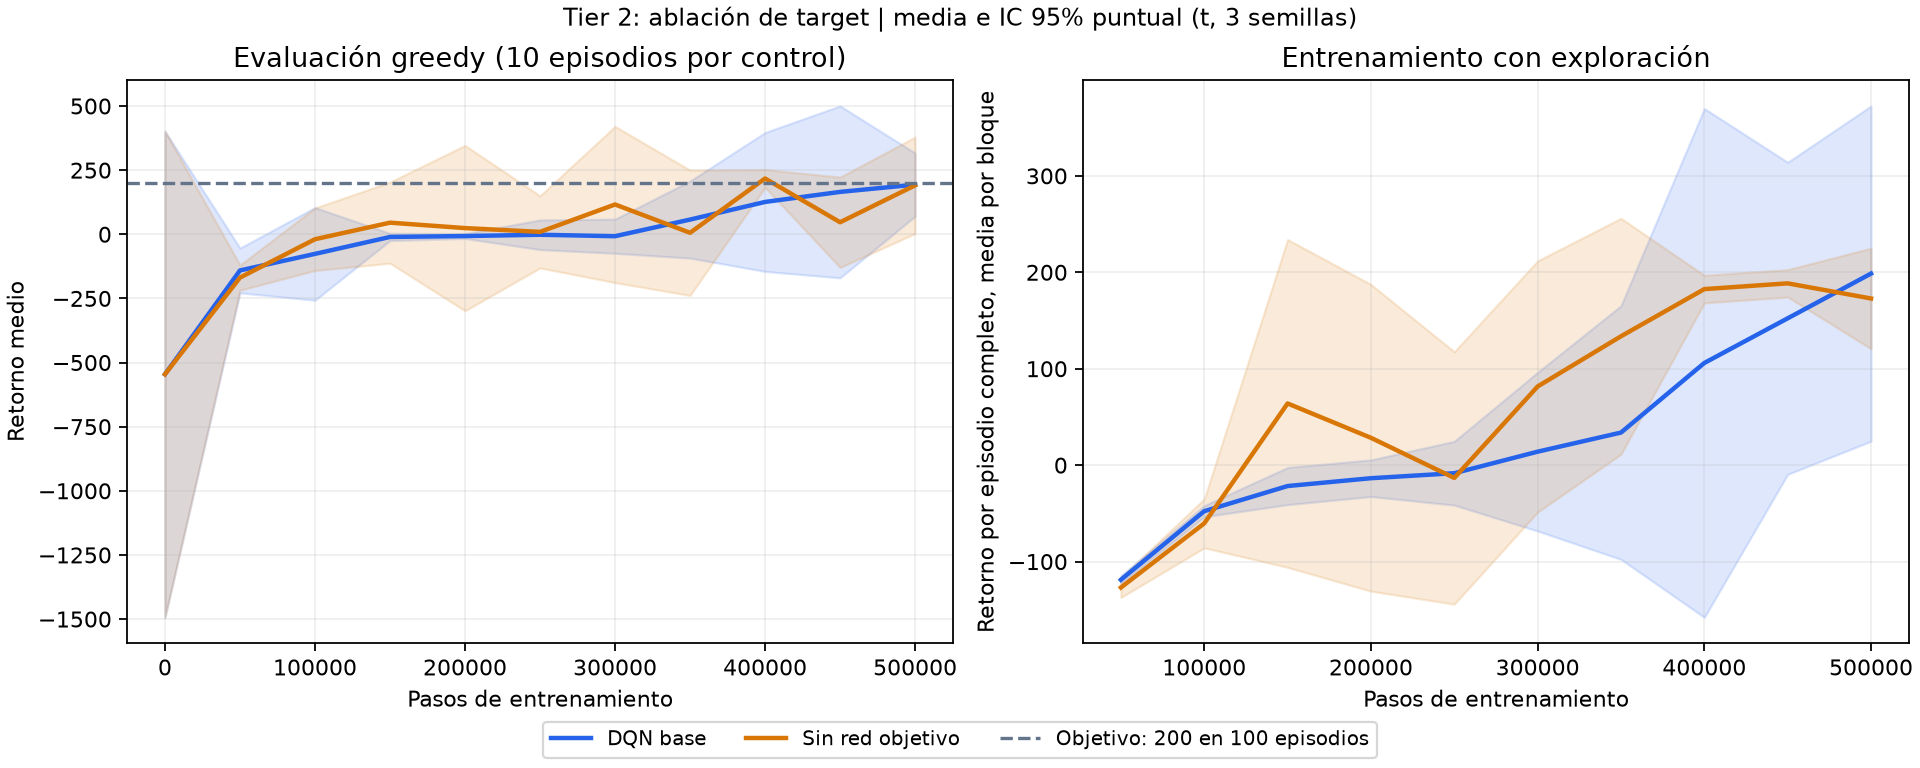

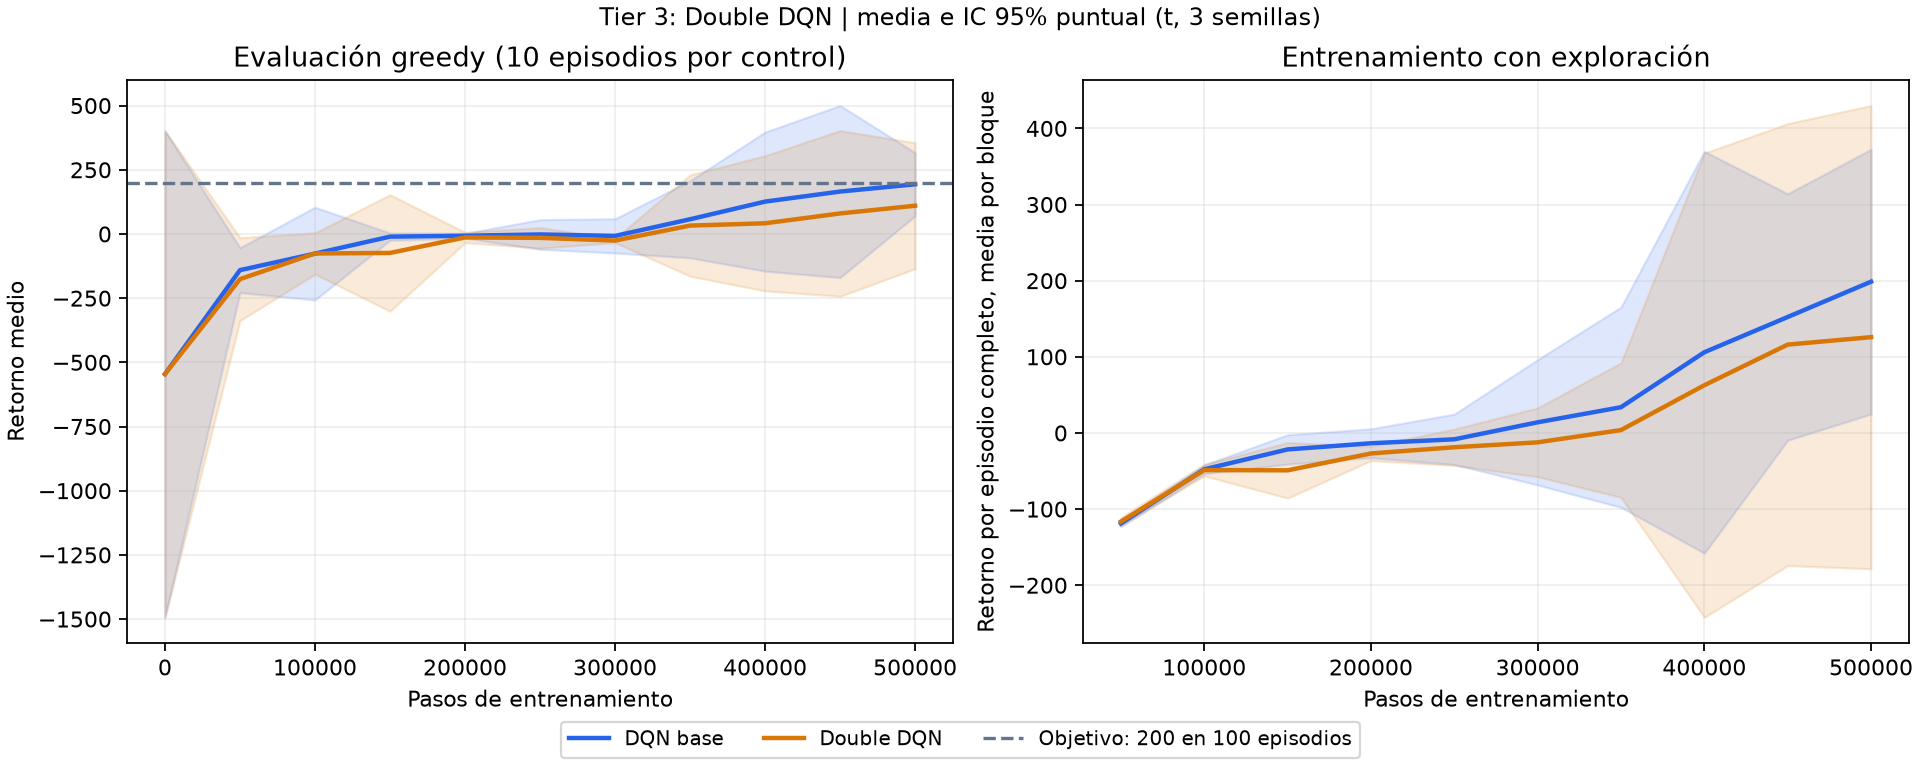

In [7]:
for nombre in ('learning_rate', 'target_sync_every', 'ablation', 'double_dqn'):
    imagen(f'results/tier23_lunarlander/figures/{nombre}.png')

## Tier 2 y Tier 3: comparación mejorada con el mismo presupuesto

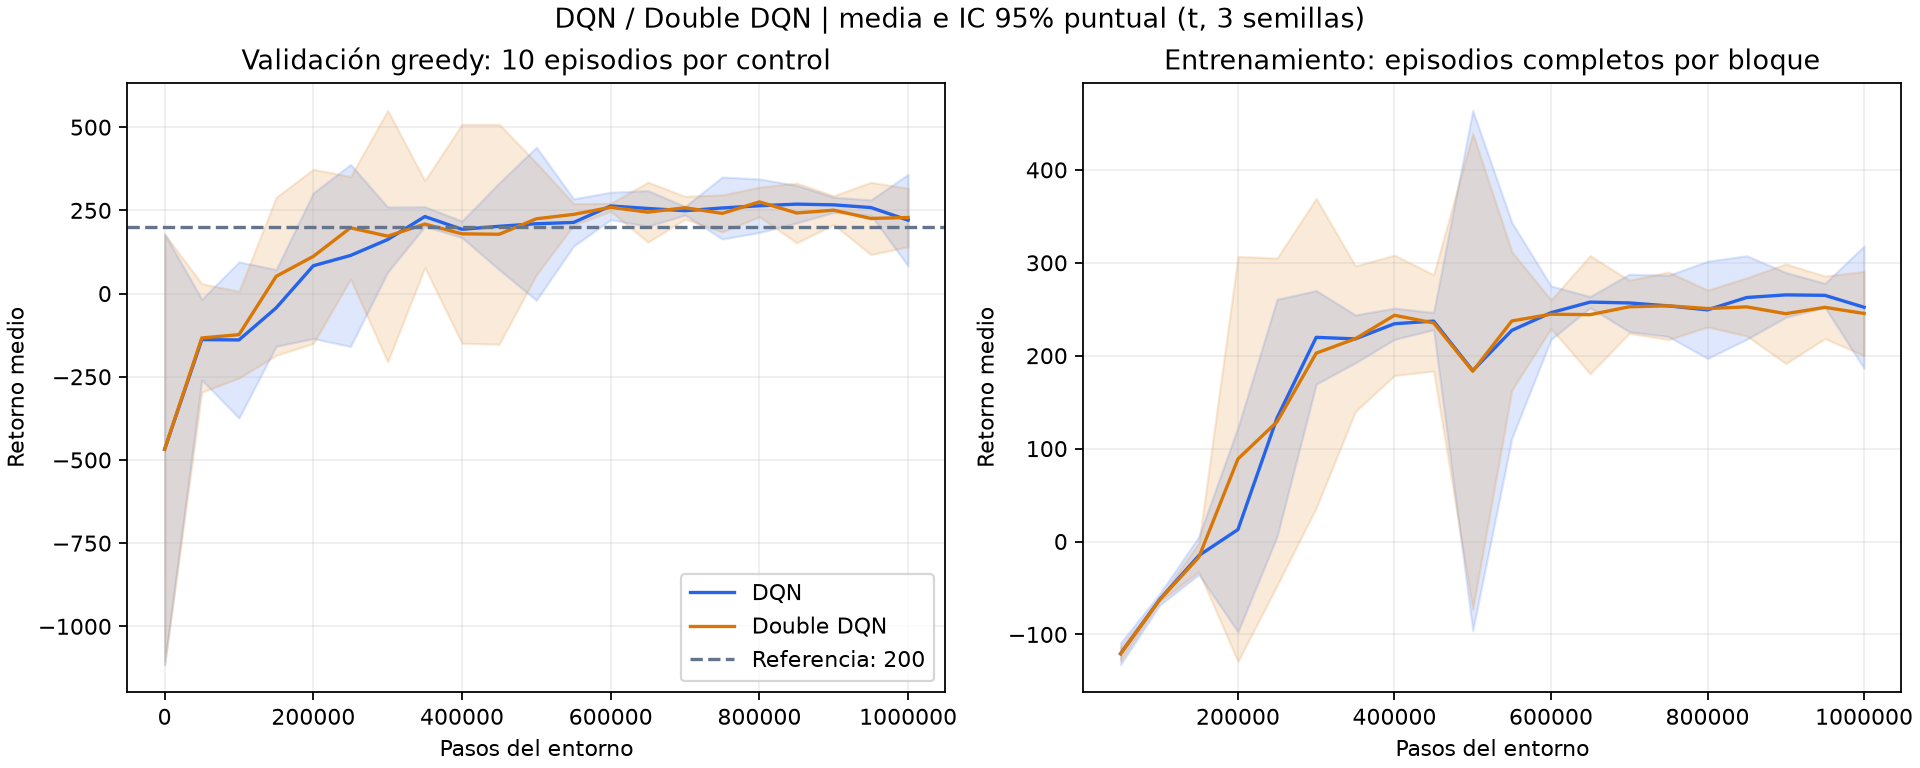

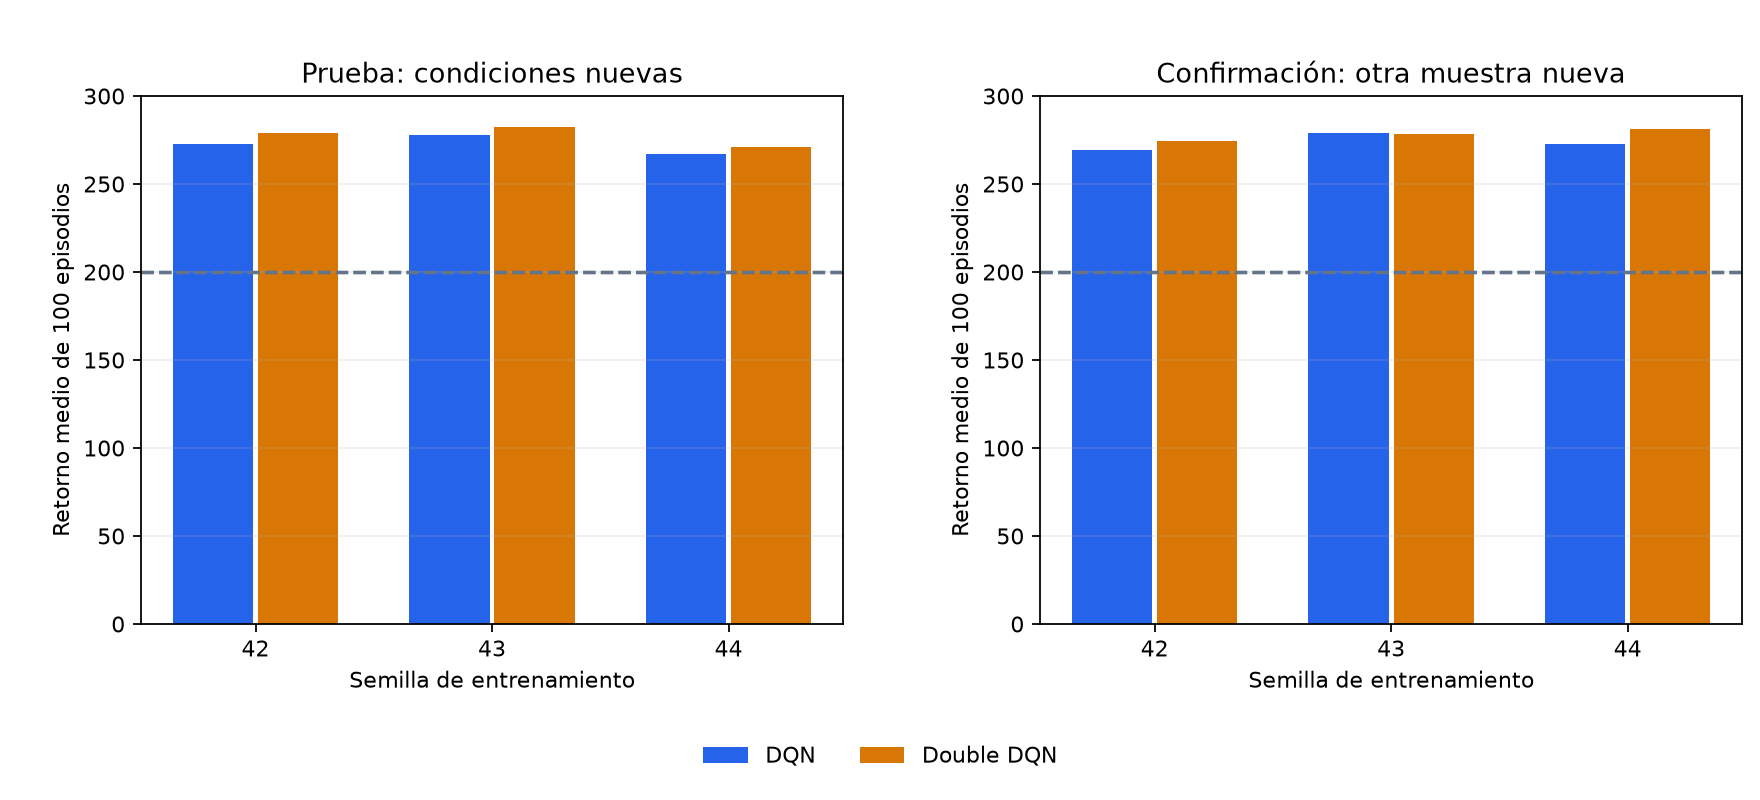

In [8]:
imagen('results/tier23_mejora_v1/figures/learning.png')
imagen('results/tier23_mejora_v1/figures/tests.png')

## Qué concluye el experimento

Los seis modelos de LunarLander superan 200 individualmente en las dos muestras.
Double DQN tiene una media algo mayor, pero la confirmación no permite afirmar
una superioridad general: el IC de sus tres diferencias emparejadas incluye cero.
Tres semillas aportan poca información sobre la distribución entre entrenamientos.
El análisis teórico y estas figuras están preparados para integrar en el artículo;
el artículo completo y la defensa oral son entregables separados.